# BIBLIOTECAS

In [1]:
## BIBLIOTECA PARA MANIPULAÇÃO DOS DADOS
import pandas as pd

## IMPORTANDO BIBLIOTECAS PARA GERAR GRÁFICOS
import matplotlib.pyplot as plt
import seaborn as sns

## IMPORTAR BIBLIOTECAS QUE CONTEM ALGORITMOS
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA

##OCULTAR WARNINGS DO CÓDIGO
import warnings
warnings.filterwarnings("ignore")

# COLETA E ENTENDIMENTO DADOS

In [3]:
df_movie = pd.read_csv('movie.csv')
df_movie.shape

(27278, 3)

In [4]:
df_movie.head()

,movieId,title,genres
0,1,Toy Story (1995),Adventure|Animation|Children|Comedy|Fantasy
1,2,Jumanji (1995),Adventure|Children|Fantasy
2,3,Grumpier Old Men (1995),Comedy|Romance
3,4,Waiting to Exhale (1995),Comedy|Drama|Romance
4,5,Father of the Bride Part II (1995),Comedy


In [7]:
df_movie.columns = [c.upper() for c in df_movie.columns]
df_movie.columns

Index(['MOVIEID', 'TITLE', 'GENRES'], dtype='object')

## ENTENDIMENTO DOS DADOS

In [8]:
##VISUALIZANDO PRIMEIRAS LINHAS DA TABELA
df_movie.head()

,MOVIEID,TITLE,GENRES
0,1,Toy Story (1995),Adventure|Animation|Children|Comedy|Fantasy
1,2,Jumanji (1995),Adventure|Children|Fantasy
2,3,Grumpier Old Men (1995),Comedy|Romance
3,4,Waiting to Exhale (1995),Comedy|Drama|Romance
4,5,Father of the Bride Part II (1995),Comedy


In [9]:
##INFORMAÇÕES SOBRE A BASE DE DADOS
df_movie.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 27278 entries, 0 to 27277
Data columns (total 3 columns):
 #   Column   Non-Null Count  Dtype 
---  ------   --------------  ----- 
 0   MOVIEID  27278 non-null  int64 
 1   TITLE    27278 non-null  object
 2   GENRES   27278 non-null  object
dtypes: int64(1), object(2)
memory usage: 639.5+ KB


In [10]:
## QTD DE VALORES UNICOS DA COLUNA
df_movie.GENRES.unique()

array(['Adventure|Animation|Children|Comedy|Fantasy',
       'Adventure|Children|Fantasy', 'Comedy|Romance', ...,
       'Action|Adventure|Animation|Fantasy|Horror',
       'Animation|Children|Comedy|Fantasy|Sci-Fi',
       'Animation|Children|Comedy|Western'], shape=(1342,), dtype=object)

In [11]:
## QTD DE VALORES UNICOS DA COLUNA
df_movie.GENRES.nunique()

1342

In [12]:
## QTD DE LINHAS PARA VALOR UNICO
df_movie.GENRES.value_counts()

,count
GENRES,
Drama,4520
Comedy,2294
Documentary,1942
Comedy|Drama,1264
Drama|Romance,1075
...,...
Action|Mystery|Romance|Western,1
Adventure|Children|Comedy|Drama|Fantasy,1
Animation|Comedy|Horror,1


## DESAFIO
- Faça o entendimento dos dados da coluna TITLE
- Quais as conclusões você chegou?

# PREPARAÇÃO DOS DADOS

## ELIMINANDO REGISTROS DUPLICADOS

In [13]:
print("- QTD REGISTROS DF ORIGINAL: ", df_movie.shape)

## ELIMINANDO REGISTRO DUPLICADOS
df_dados = df_movie.drop_duplicates('TITLE')

print("- QTD REGISTROS DF NOVO: ", df_dados.shape)

- QTD REGISTROS DF ORIGINAL:  (27278, 3)
- QTD REGISTROS DF NOVO:  (27262, 3)


## PADRONIZAR TEXTOS

In [14]:
## VALORES ÚNICOS NA COLUNA
df_dados.TITLE.unique()

array(['Toy Story (1995)', 'Jumanji (1995)', 'Grumpier Old Men (1995)',
       ..., 'The Pirates (2014)', 'Rentun Ruusu (2001)',
       'Innocence (2014)'], shape=(27262,), dtype=object)

In [15]:
## CONVERTENDO TEXTO PARA MAIUSCULO
df_dados.loc[:,'TITLE'] = df_dados.TITLE.str.upper()

In [16]:
df_dados.TITLE.unique()

array(['TOY STORY (1995)', 'JUMANJI (1995)', 'GRUMPIER OLD MEN (1995)',
       ..., 'THE PIRATES (2014)', 'RENTUN RUUSU (2001)',
       'INNOCENCE (2014)'], shape=(27262,), dtype=object)

## DESAFIO
- Padronize os valores da conluna GENRES
- Valide se o procedimento foi correto

In [17]:
df_dados.loc[:,'GENRES'] = df_dados.GENRES.str.upper()

df_dados['GENRES'].unique()

array(['ADVENTURE|ANIMATION|CHILDREN|COMEDY|FANTASY',
       'ADVENTURE|CHILDREN|FANTASY', 'COMEDY|ROMANCE', ...,
       'ACTION|ADVENTURE|ANIMATION|FANTASY|HORROR',
       'ANIMATION|CHILDREN|COMEDY|FANTASY|SCI-FI',
       'ANIMATION|CHILDREN|COMEDY|WESTERN'], shape=(1342,), dtype=object)

## CRIAR COLUNAS

In [18]:
df_dados

,MOVIEID,TITLE,GENRES
0,1,TOY STORY (1995),ADVENTURE|ANIMATION|CHILDREN|COMEDY|FANTASY
1,2,JUMANJI (1995),ADVENTURE|CHILDREN|FANTASY
2,3,GRUMPIER OLD MEN (1995),COMEDY|ROMANCE
3,4,WAITING TO EXHALE (1995),COMEDY|DRAMA|ROMANCE
4,5,FATHER OF THE BRIDE PART II (1995),COMEDY
...,...,...,...
27273,131254,KEIN BUND FÜR'S LEBEN (2007),COMEDY
27274,131256,"FEUER, EIS & DOSENBIER (2002)",COMEDY
27275,131258,THE PIRATES (2014),ADVENTURE
27276,131260,RENTUN RUUSU (2001),(NO GENRES LISTED)


In [19]:
## EXTRAINDO ANO DO FILME E CRIANDO NOVA COLUNA
df_dados['ANO_FILME'] = df_dados.TITLE.str[-5:-1]
df_dados

,MOVIEID,TITLE,GENRES,ANO_FILME
0,1,TOY STORY (1995),ADVENTURE|ANIMATION|CHILDREN|COMEDY|FANTASY,1995
1,2,JUMANJI (1995),ADVENTURE|CHILDREN|FANTASY,1995
2,3,GRUMPIER OLD MEN (1995),COMEDY|ROMANCE,1995
3,4,WAITING TO EXHALE (1995),COMEDY|DRAMA|ROMANCE,1995
4,5,FATHER OF THE BRIDE PART II (1995),COMEDY,1995
...,...,...,...,...
27273,131254,KEIN BUND FÜR'S LEBEN (2007),COMEDY,2007
27274,131256,"FEUER, EIS & DOSENBIER (2002)",COMEDY,2002
27275,131258,THE PIRATES (2014),ADVENTURE,2014
27276,131260,RENTUN RUUSU (2001),(NO GENRES LISTED),2001


In [20]:
df_dados.ANO_FILME.unique()

array(['1995', '1994', '1996', '1976', '1992', '1988', '1967', '1993',
       '1964', '1977', '1965', '1982', '1985', '1990', '1991', '1989',
       '1937', '1940', '1969', '1981', '1973', '1970', '1960', '1955',
       '1959', '1968', '1980', '1975', '1986', '1948', '1943', '1950',
       '1946', '1987', '1997', '1974', '1956', '1958', '1949', '1972',
       '1998', '1933', '1952', '1951', '1957', '1961', '1954', '1934',
       '1944', '1963', '1942', '1941', '1953', '1939', '1947', '1945',
       '1938', '1935', '1936', '1926', '1932', '1979', '1971', '1978',
       '1966', '1962', '1983', '1984', '1931', '1922', '1999', '1927',
       '1929', '1930', '1928', '1925', '1914', '2000', '1919', '1923',
       '1920', '1918', '1921', '2001', '1924', '2002', '2003', '1915',
       '2004', '1916', '002)', '1917', '948)', '965)', '2005', '2006',
       '1902', 'LON ', '1903', '2007', '998)', '2008', '2009', '1912',
       '2010', 'PIEL', '010)', '008)', '1913', '2011', '1898', '1899',
      

## DESAFIO
- Faça a validação dos valores da coluna ANO_FILME
- Quais as conclusões?

In [21]:
display(df_dados.query("ANO_FILME == 'N MA' ") )

display(df_dados.query("ANO_FILME == 'GÓWN' ") )

,MOVIEID,TITLE,GENRES,ANO_FILME
26974,129705,MY OWN MAN,(NO GENRES LISTED),N MA


,MOVIEID,TITLE,GENRES,ANO_FILME
26784,128734,POLSKIE GÓWNO,COMEDY|MUSICAL,GÓWN


## VERIFICANDO VALORES NULOS

In [23]:
## VERIFICANDO VALORES NULOS
df_dados.isnull().sum()

,0
MOVIEID,0
TITLE,0
GENRES,0
ANO_FILME,26


In [24]:
## ANALISANDO REGISTROS NULOS
df_dados.query(" ANO_FILME.isnull() ")

,MOVIEID,TITLE,GENRES,ANO_FILME
7481,7789,"11'09\\""01 - SEPTEMBER 11 (2002)""",DRAMA,NaN
10593,40697,BABYLON 5,SCI-FI,NaN
11677,51372,"\\""GREAT PERFORMANCES\""\"" CATS (1998)""",MUSICAL,NaN
15646,79607,"MILLIONS GAME, THE (DAS MILLIONENSPIEL)",ACTION|DRAMA|SCI-FI|THRILLER,NaN
17341,87442,"BICYCLE, SPOON, APPLE (BICICLETA, CULLERA, POMA)",DOCUMENTARY,NaN
19859,98063,MONA AND THE TIME OF BURNING LOVE (MONA JA PAL...,DRAMA,NaN
22368,107434,DIPLOMATIC IMMUNITY (2009– ),COMEDY,NaN
22669,108548,"BIG BANG THEORY, THE (2007-)",COMEDY,NaN
22679,108583,FAWLTY TOWERS (1975-1979),COMEDY,NaN
23617,112406,BRAZIL: IN THE SHADOW OF THE STADIUMS,DOCUMENTARY,NaN


In [25]:
print("- QTD DADOS ORIGINAL: ", df_dados.shape )

## EXCLUINDO REGISTROS SEM GENERO E COM ANO EM BRANCO
df_limpos = df_dados.query("GENRES != '(NO GENRES LISTED)' and ~ANO_FILME.isnull()")

print("- QTD DADOS NOVOS: ", df_limpos.shape)

- QTD DADOS ORIGINAL:  (27262, 4)
- QTD DADOS NOVOS:  (26999, 4)


In [26]:
display( df_limpos.query("GENRES == '(NO GENRES LISTED)' ") )

display( df_limpos.query("ANO_FILME.isnull()") )

,MOVIEID,TITLE,GENRES,ANO_FILME


,MOVIEID,TITLE,GENRES,ANO_FILME


## CONVERTER TEXTO PARA NÚMERO

In [27]:
df_limpos.info()

<class 'pandas.core.frame.DataFrame'>
Index: 26999 entries, 0 to 27277
Data columns (total 4 columns):
 #   Column     Non-Null Count  Dtype 
---  ------     --------------  ----- 
 0   MOVIEID    26999 non-null  int64 
 1   TITLE      26999 non-null  object
 2   GENRES     26999 non-null  object
 3   ANO_FILME  26999 non-null  object
dtypes: int64(1), object(3)
memory usage: 1.0+ MB


In [32]:
## CONVERTER TEXTO PARA NÚMERO
df_limpos["ANO_FILME"] = df_limpos.ANO_FILME.astype(int)

In [33]:
df_limpos.info()

<class 'pandas.core.frame.DataFrame'>
Index: 26999 entries, 0 to 27277
Data columns (total 4 columns):
 #   Column     Non-Null Count  Dtype 
---  ------     --------------  ----- 
 0   MOVIEID    26999 non-null  int64 
 1   TITLE      26999 non-null  object
 2   GENRES     26999 non-null  object
 3   ANO_FILME  26999 non-null  int64 
dtypes: int64(2), object(2)
memory usage: 1.0+ MB


# TRANSFORMAÇÃO DA BASE DE DADOS

## CONVERTENDO GENEROS EM REGISTROS ÚNICO

In [34]:
## VALORES UNICOS
print( df_limpos['GENRES'].unique() )
print()
print("- QTD DE GENEROS ÚNICOS: ",  df_limpos['GENRES'].nunique() )

['ADVENTURE|ANIMATION|CHILDREN|COMEDY|FANTASY'
 'ADVENTURE|CHILDREN|FANTASY' 'COMEDY|ROMANCE' ...
 'ACTION|ADVENTURE|ANIMATION|FANTASY|HORROR'
 'ANIMATION|CHILDREN|COMEDY|FANTASY|SCI-FI'
 'ANIMATION|CHILDREN|COMEDY|WESTERN']

- QTD DE GENEROS ÚNICOS:  1341


In [36]:
## ELIMINANDO GENEROS DUPLICADOS
lista_generos = df_limpos[['GENRES']].drop_duplicates("GENRES")
lista_generos.shape

(1341, 1)

In [37]:
## TRANSFORMANDO A COMBINAÇÃO DE GENEROS EM LISTA
lista_generos = df_limpos[['GENRES']].GENRES.str.split("|")
lista_generos

,GENRES
0,"[ADVENTURE, ANIMATION, CHILDREN, COMEDY, FANTASY]"
1,"[ADVENTURE, CHILDREN, FANTASY]"
2,"[COMEDY, ROMANCE]"
3,"[COMEDY, DRAMA, ROMANCE]"
4,[COMEDY]
...,...
27272,"[COMEDY, HORROR]"
27273,[COMEDY]
27274,[COMEDY]
27275,[ADVENTURE]


In [38]:
## TRANSFORMANDO CADA GENERO EM UMA LINHA
lista_generos = lista_generos.explode()
lista_generos

,GENRES
0,ADVENTURE
0,ANIMATION
0,CHILDREN
0,COMEDY
0,FANTASY
...,...
27274,COMEDY
27275,ADVENTURE
27277,ADVENTURE
27277,FANTASY


In [39]:
## ANALISANDO A DISTRIBUIÇÃO DOS GENEROS
qtd_genero = lista_generos.value_counts(normalize=True)*100
qtd_genero

,proportion
GENRES,
DRAMA,24.636342
COMEDY,15.459402
THRILLER,7.720459
ROMANCE,7.620650
ACTION,6.500564
CRIME,5.428534
HORROR,4.822283
DOCUMENTARY,4.559821
ADVENTURE,4.302904


In [40]:
## QUANTIDADE DE GENEROS UNICO
print("- QTD DE GENEROS ÚNICOS: ", len(qtd_genero) )

- QTD DE GENEROS ÚNICOS:  19


## ONE-HOT-ENCODING DOS GENEROS
- transformar linhas em colunas

## DESAFIO
- Aplique a transformação OHE na coluna de GENRES
- **Dica 1**: ao final a tabela tem que estar igual ne exposição da aula, ou seja, as linhas em colunas com 1/0
  além dos generos, adicione o TÍTULO e ANO_FILME na tabela
- Pode utilizar a IA para desenvolver este procedimento

In [43]:
## EXTRAINDO APENAS O ANO DO TÍTULO COM EXPRESSÃO REGULAR
df_dados['ANO_FILME'] = df_dados["TITLE"].str.extract(r"\((\d{4})\)\s*$")
df_dados.ANO_FILME.unique()

array(['1995', '1994', '1996', '1976', '1992', '1988', '1967', '1993',
       '1964', '1977', '1965', '1982', '1985', '1990', '1991', '1989',
       '1937', '1940', '1969', '1981', '1973', '1970', '1960', '1955',
       '1959', '1968', '1980', '1975', '1986', '1948', '1943', '1950',
       '1946', '1987', '1997', '1974', '1956', '1958', '1949', '1972',
       '1998', '1933', '1952', '1951', '1957', '1961', '1954', '1934',
       '1944', '1963', '1942', '1941', '1953', '1939', '1947', '1945',
       '1938', '1935', '1936', '1926', '1932', '1979', '1971', '1978',
       '1966', '1962', '1983', '1984', '1931', '1922', '1999', '1927',
       '1929', '1930', '1928', '1925', '1914', '2000', '1919', '1923',
       '1920', '1918', '1921', '2001', '1924', '2002', '2003', '1915',
       '2004', '1916', nan, '1917', '2005', '2006', '1902', '1903',
       '2007', '2008', '2009', '1912', '2010', '1913', '2011', '1898',
       '1899', '1894', '2012', '1909', '1910', '1901', '1893', '2013',
       '1

# MODELO ML

## SELEÇÃO VARIÁVEIS

In [48]:
## REALIZANDO O ONE-HOT ENCODING (OHE) PARA DEFINIR DF_TRANSF
df_generos_ohe = df_limpos['GENRES'].str.get_dummies('|')
df_transf = pd.concat([df_limpos[['TITLE', 'ANO_FILME']], df_generos_ohe], axis=1)

## EXIBINDO AS PRIMEIRAS LINHAS DO DATAFRAME TRANSFORMADO
df_transf.head()

,TITLE,ANO_FILME,ACTION,ADVENTURE,ANIMATION,CHILDREN,COMEDY,CRIME,DOCUMENTARY,DRAMA,...,FILM-NOIR,HORROR,IMAX,MUSICAL,MYSTERY,ROMANCE,SCI-FI,THRILLER,WAR,WESTERN
0,TOY STORY (1995),1995,0,1,1,1,1,0,0,0,...,0,0,0,0,0,0,0,0,0,0
1,JUMANJI (1995),1995,0,1,0,1,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
2,GRUMPIER OLD MEN (1995),1995,0,0,0,0,1,0,0,0,...,0,0,0,0,0,1,0,0,0,0
3,WAITING TO EXHALE (1995),1995,0,0,0,0,1,0,0,1,...,0,0,0,0,0,1,0,0,0,0
4,FATHER OF THE BRIDE PART II (1995),1995,0,0,0,0,1,0,0,0,...,0,0,0,0,0,0,0,0,0,0


In [49]:
## CRIANDO DF PARA TREINAR O MODELO APENAS COM AS COLUNAS CORRETAS
df_modelo = df_transf.drop(columns=['TITLE','ANO_FILME'])
df_modelo.head()

,ACTION,ADVENTURE,ANIMATION,CHILDREN,COMEDY,CRIME,DOCUMENTARY,DRAMA,FANTASY,FILM-NOIR,HORROR,IMAX,MUSICAL,MYSTERY,ROMANCE,SCI-FI,THRILLER,WAR,WESTERN
0,0,1,1,1,1,0,0,0,1,0,0,0,0,0,0,0,0,0,0
1,0,1,0,1,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0
2,0,0,0,0,1,0,0,0,0,0,0,0,0,0,1,0,0,0,0
3,0,0,0,0,1,0,0,1,0,0,0,0,0,0,1,0,0,0,0
4,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0


In [51]:
## CRIANDO LISTA COM AS VARIÁVEIS(COLUNAS) DO MODELO
# este modelo é necessário para executar o modelo para recomendações
colunas_modelo = df_modelo.columns
colunas_modelo

Index(['ACTION', 'ADVENTURE', 'ANIMATION', 'CHILDREN', 'COMEDY', 'CRIME',
       'DOCUMENTARY', 'DRAMA', 'FANTASY', 'FILM-NOIR', 'HORROR', 'IMAX',
       'MUSICAL', 'MYSTERY', 'ROMANCE', 'SCI-FI', 'THRILLER', 'WAR',
       'WESTERN'],
      dtype='object')

## TREINANDO ALGORITMO

In [52]:
## CRIANDO ALGORITMO
kmeans = KMeans(n_clusters = 3, random_state=123)

## TREINANDO ALGORITMO
kmeans.fit(df_modelo)

KMeans(n_clusters=3, random_state=123)

In [53]:
## INSERINDO CADA REGISTRO EM UM CLUSTER(GRUPO)
# salvando o rótulo em uma nova coluna
df_limpos.loc[:,'CLUSTER'] = kmeans.predict(df_modelo)

df_limpos.CLUSTER.unique()

array([2, 1, 0], dtype=int32)

In [54]:
df_limpos.head()

,MOVIEID,TITLE,GENRES,ANO_FILME,CLUSTER
0,1,TOY STORY (1995),ADVENTURE|ANIMATION|CHILDREN|COMEDY|FANTASY,1995,2
1,2,JUMANJI (1995),ADVENTURE|CHILDREN|FANTASY,1995,1
2,3,GRUMPIER OLD MEN (1995),COMEDY|ROMANCE,1995,2
3,4,WAITING TO EXHALE (1995),COMEDY|DRAMA|ROMANCE,1995,2
4,5,FATHER OF THE BRIDE PART II (1995),COMEDY,1995,2


## AVALIANDO ALGORITMO

In [55]:
## QUANTIDADE DE FILMES EM CADA CLUSTER
df_plot = df_limpos.groupby('CLUSTER').agg(QTD_FILMES = ('TITLE','count')).reset_index()
df_plot

,CLUSTER,QTD_FILMES
0,0,2447
1,1,7863
2,2,16689


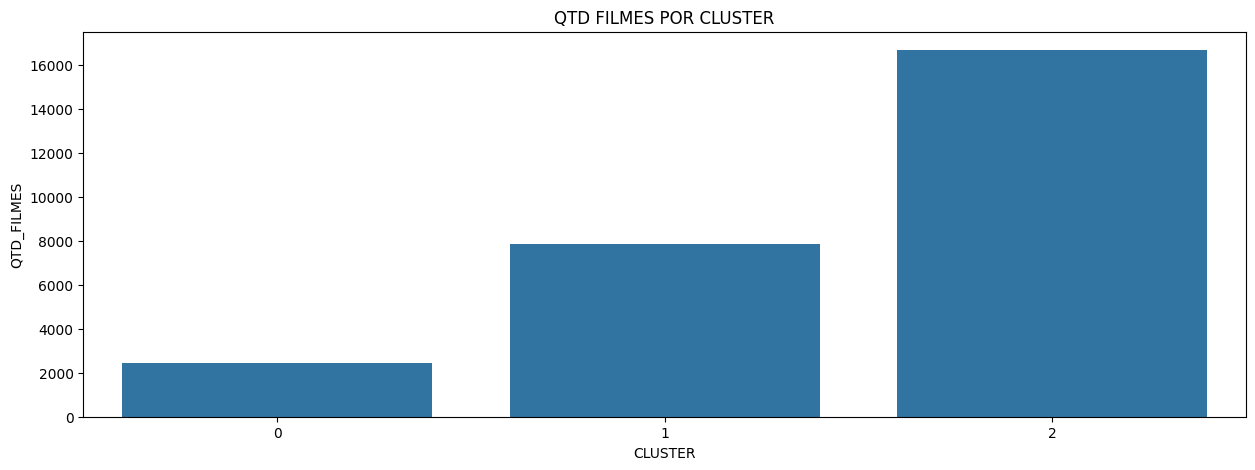

In [56]:
## GRÁFICO COM A QUANTIDADE DE REGISTROS
plt.figure(figsize=(15,5))
sns.barplot(x = 'CLUSTER', y = 'QTD_FILMES', data = df_plot)
plt.title("QTD FILMES POR CLUSTER")
plt.show()

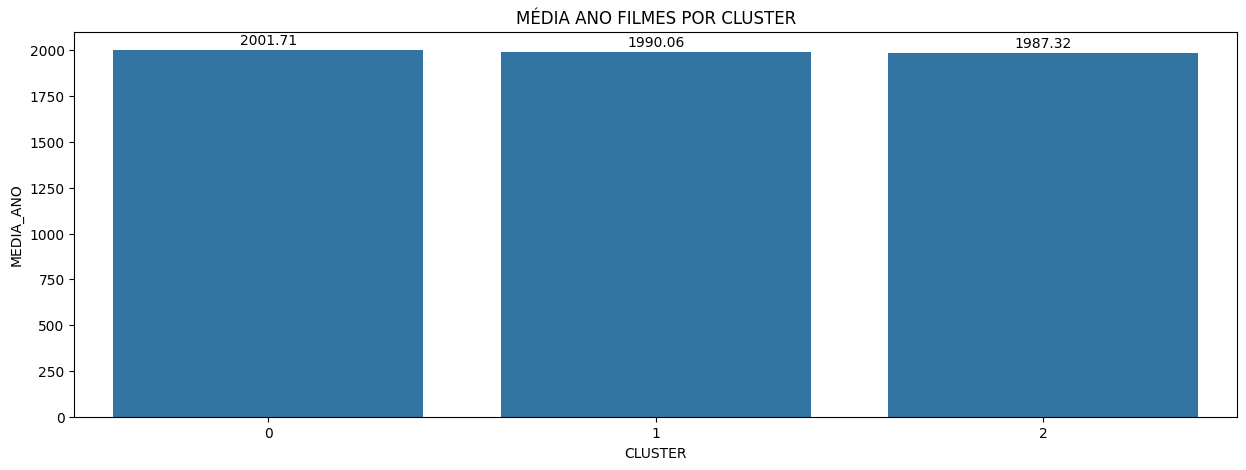

In [57]:
## MÉDIA DE ANOS EM CADA CLUSTER
df_plot = df_limpos.groupby('CLUSTER').agg(MEDIA_ANO = ('ANO_FILME','mean')).reset_index()
df_plot

## GRÁFICO COM A QUANTIDADE DE REGISTROS
plt.figure(figsize=(15,5))
grafico = sns.barplot(x = 'CLUSTER', y = 'MEDIA_ANO', data = df_plot)

for container in grafico.containers:
    grafico.bar_label(container, fmt="%.2f",padding=2)

plt.title("MÉDIA ANO FILMES POR CLUSTER")
plt.show()

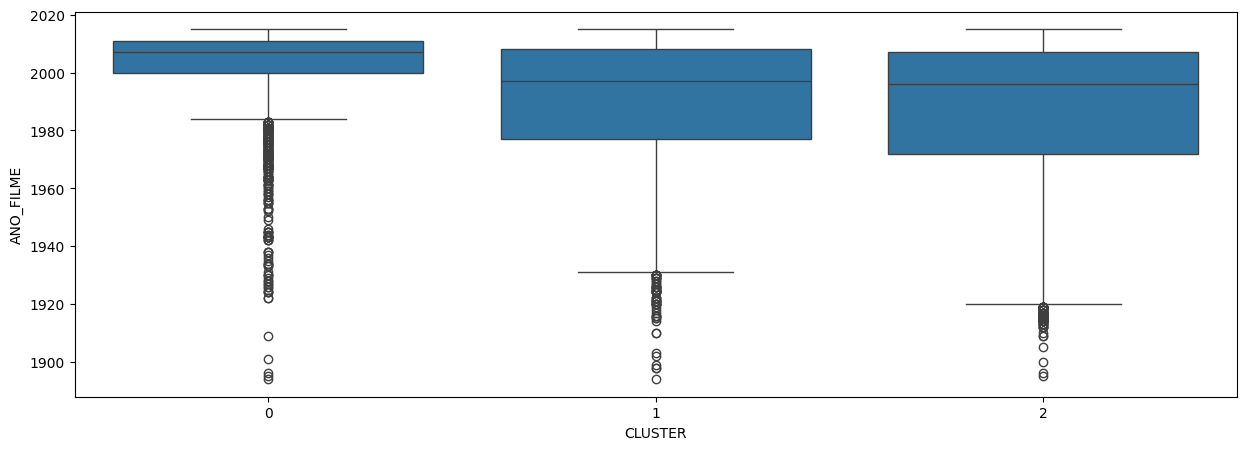

In [58]:
plt.figure(figsize=(15,5))
sns.boxplot(x = 'CLUSTER', y = 'ANO_FILME', data = df_limpos)
plt.show()

In [59]:
# Redução para duas dimensões
pca = PCA( n_components=2, random_state=42)

#componentes = pca.fit_transform(X_padronizado) # APAGAR
componentes = pca.fit_transform(df_modelo)
componentes

array([[-0.99389464,  0.23122615],
       [-0.40801716, -0.36327642],
       [-0.72867781,  0.69923131],
       ...,
       [-0.76033136,  0.35403247],
       [-0.29566109, -0.34849877],
       [-0.41493556, -0.60500868]], shape=(26999, 2))

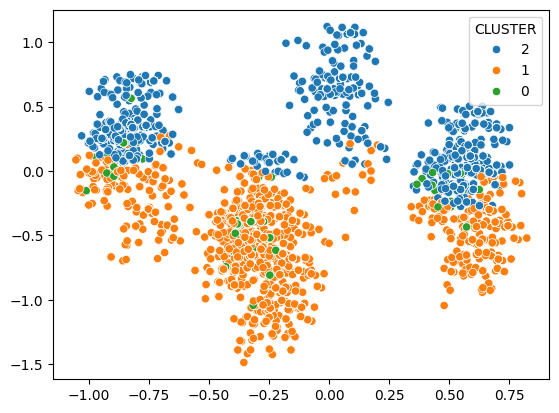

In [60]:
sns.scatterplot(x = componentes[:, 0], y = componentes[:, 1], hue = df_limpos.CLUSTER.astype(str))
plt.show()

In [64]:
## AVALIANDO AS CARACTERÍSTICAS DE CADA CLUSTER

## RETORNANDO OS CENTROS(centroides) DE CADA GENERO NOS CLUSTER
centros = kmeans.cluster_centers_
centros

array([[ 3.26930936e-03,  1.75725378e-02,  6.12995505e-03,
         2.04331835e-03,  4.49530037e-02,  1.63465468e-02,
         1.00000000e+00,  4.08663670e-02,  2.45198202e-03,
        -3.10515502e-16,  7.76460973e-03,  1.18512464e-02,
         4.04577033e-02,  4.08663670e-03,  4.49530037e-03,
         4.49530037e-03,  3.67797303e-03,  3.31017573e-02,
         8.17327340e-04],
       [ 3.18482688e-01,  1.75407332e-01,  7.48472505e-02,
         6.03360489e-02,  8.00661914e-02,  2.00738289e-01,
         3.81873727e-04,  2.34088595e-01,  9.39409369e-02,
         2.06211813e-02,  2.80549898e-01,  1.56568228e-02,
         2.44399185e-02,  1.32255601e-01,  4.04786151e-02,
         1.76680244e-01,  5.12856415e-01,  2.82586558e-02,
         4.84979633e-02],
       [ 6.03138476e-02,  5.43243891e-02,  2.52156205e-02,
         3.94705319e-02,  4.56696215e-01,  7.90608529e-02,
         1.01820795e-03,  6.82199329e-01,  3.98897940e-02,
         1.00622904e-02,  2.31193100e-02,  2.63536176e-03,
    

In [62]:
## CRIANDO UM DATAFRAME COM OS VALORES DE CENTROS
df_centros = pd.DataFrame(centros, columns = colunas_modelo)
df_centros['CLUSTER'] = df_limpos['CLUSTER'].astype(str).unique()
df_centros.head()

,ACTION,ADVENTURE,ANIMATION,CHILDREN,COMEDY,CRIME,DOCUMENTARY,DRAMA,FANTASY,FILM-NOIR,HORROR,IMAX,MUSICAL,MYSTERY,ROMANCE,SCI-FI,THRILLER,WAR,WESTERN,CLUSTER
0,0.003269,0.017573,0.006130,0.002043,0.044953,0.016347,1.000000,0.040866,0.002452,-3.105155e-16,0.007765,0.011851,0.040458,0.004087,0.004495,0.004495,0.003678,0.033102,0.000817,2
1,0.318483,0.175407,0.074847,0.060336,0.080066,0.200738,0.000382,0.234089,0.093941,2.062118e-02,0.280550,0.015657,0.024440,0.132256,0.040479,0.176680,0.512856,0.028259,0.048498,1
2,0.060314,0.054324,0.025216,0.039471,0.456696,0.079061,0.001018,0.682199,0.039890,1.006229e-02,0.023119,0.002635,0.044502,0.027791,0.227240,0.020244,0.008325,0.053366,0.017549,0


In [63]:
## CONVERTENDO COLUNAS EM LINHAS
df_centros = df_centros.melt(id_vars=['CLUSTER'], var_name='GENERO',value_name='CENTRO')
df_centros.head()

,CLUSTER,GENERO,CENTRO
0,2,ACTION,0.003269
1,1,ACTION,0.318483
2,0,ACTION,0.060314
3,2,ADVENTURE,0.017573
4,1,ADVENTURE,0.175407


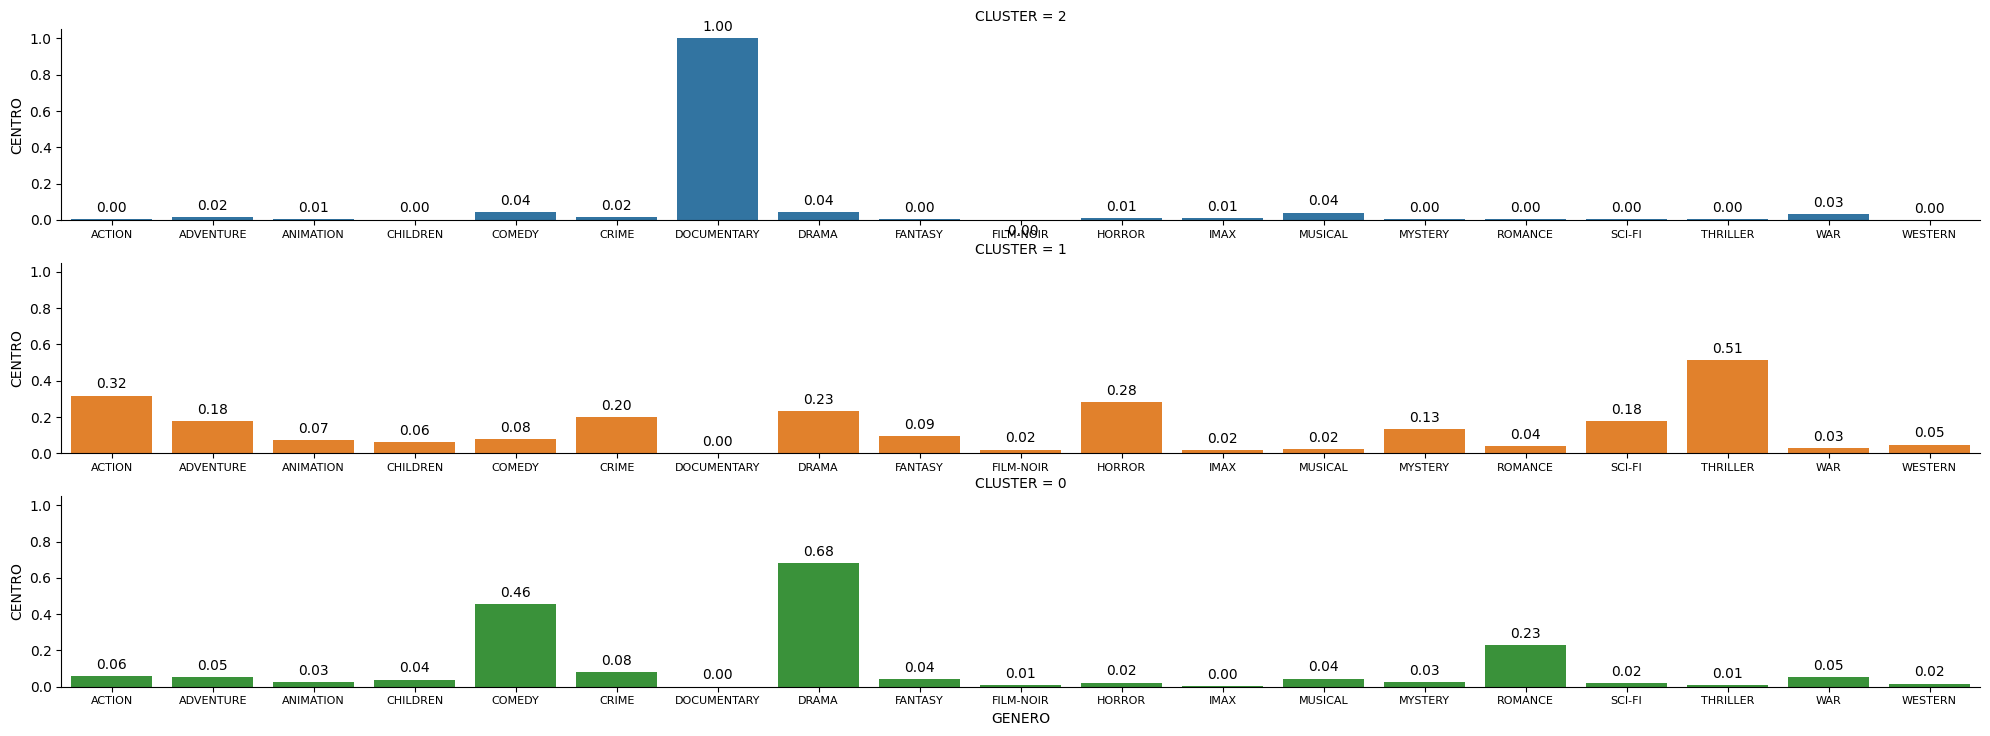

In [65]:
## GERANDO GRÁFICO PARA ANALISAR O PERFIL DE CADA CLUSTER
grafico = sns.catplot(
    data=df_centros,
    x = 'GENERO',
    y = 'CENTRO',
    hue = 'CLUSTER',
    row = 'CLUSTER',
    kind = 'bar',
    height = 2.5,
    aspect = 8,
    legend = False
)

## INSERINDO RÓTULOS EM CADA BARRA
for ax in grafico.axes.flat:
    ax.tick_params(axis = 'x', labelbottom = True, labelsize = 8)

    for container in ax.containers:
        ax.bar_label(container, fmt="%.2f",padding=3)

## DESAFIO
- Treine um novo algoritmo alterando a quantidade de cluster.
- Treine com 10 ou 15 clusters

QUAL O MELHOR ALGORITMO, NA SUA OPINIÃO?

## SALVANDO MODELO FINAL

In [ ]:
## BIBLIOTECA PARA SALAR O MODELO
import joblib as jb

In [ ]:
colunas_modelo

In [ ]:
kmeans

In [ ]:
df_limpos.head()

In [ ]:
## CRIANDO OBJETO COM MODELO E ATRIBUTOS
dict_modelo ={
    "BASE_DADOS": df_limpos,
    "VARIAVEIS": colunas_modelo,
    "MODELO": kmeans,
}

dict_modelo

In [ ]:
## SALVANDO MODELO
jb.dump(dict_modelo, "modelo.pkl")

In [ ]:
import joblib as jb
import pandas as pd
from sklearn.metrics import euclidean_distances